In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    auc
)

pd.set_option("display.max_columns", 100)
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
DATA_FILENAME = "merged hospital deterioration hourly panel dataset.csv"
DATA_PATH_CANDIDATES = [
    Path(DATA_FILENAME),
    Path("data") / DATA_FILENAME,
    Path("Hospital_Deterioration_Clean_Start_Package") / DATA_FILENAME,
]
DATA_PATH = next((candidate for candidate in DATA_PATH_CANDIDATES if candidate.exists()), None)

if DATA_PATH is None:
    searched = "\n".join(str(p.resolve()) for p in DATA_PATH_CANDIDATES)
    raise FileNotFoundError(
        "Dataset CSV not found. Place it beside the notebook or in the data/ folder.\n"
        f"Checked these paths:\n{searched}"
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully from:", DATA_PATH.resolve())
print("Shape:", df.shape)
print("Unique patients:", df["patient_id"].nunique())
display(df.head())

Dataset loaded successfully from: C:\Users\garvd\merged hospital deterioration hourly panel dataset.csv
Shape: (417866, 27)
Unique patients: 10000


,patient_id,hour_from_admission,heart_rate,respiratory_rate,spo2_pct,temperature_c,systolic_bp,diastolic_bp,oxygen_device,oxygen_flow,mobility_score,nurse_alert,wbc_count,lactate,creatinine,crp_level,hemoglobin,sepsis_risk_score,age,gender,comorbidity_index,admission_type,baseline_risk_score,los_hours,deterioration_event,deterioration_within_12h_from_admission,deterioration_hour
0,1,0,68.58,14.47,96.52,37.18,108.94,78.43,none,0.0,2,0,5.68,1.28,1.27,10.66,13.55,0.2621,24,M,2,Elective,0.2173,17,0,0,-1
1,1,1,67.03,13.87,94.94,37.25,111.73,79.14,none,0.0,3,0,5.46,1.18,1.22,11.94,13.65,0.3353,24,M,2,Elective,0.2173,17,0,0,-1
2,1,2,69.05,14.63,94.45,37.29,111.48,78.86,none,0.0,2,0,5.55,1.21,1.25,10.24,13.69,0.1678,24,M,2,Elective,0.2173,17,0,0,-1
3,1,3,69.07,14.42,95.16,37.27,110.68,76.79,none,0.0,2,0,5.50,1.13,1.24,10.72,13.61,0.1961,24,M,2,Elective,0.2173,17,0,0,-1
4,1,4,73.35,15.62,95.83,37.21,110.38,75.47,none,0.0,3,0,5.96,1.20,1.21,11.46,13.49,0.3000,24,M,2,Elective,0.2173,17,0,0,-1


In [3]:
print("Dataset shape:", df.shape)
print("Unique patients:", df["patient_id"].nunique())
print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isna().sum().sum())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (417866, 27)
Unique patients: 10000
Duplicate rows: 0
Total missing values: 0

Data types:


,Data Type
patient_id,int64
hour_from_admission,int64
heart_rate,float64
respiratory_rate,float64
spo2_pct,float64
temperature_c,float64
systolic_bp,float64
diastolic_bp,float64
oxygen_device,object
oxygen_flow,float64



Columns:
['patient_id', 'hour_from_admission', 'heart_rate', 'respiratory_rate', 'spo2_pct', 'temperature_c', 'systolic_bp', 'diastolic_bp', 'oxygen_device', 'oxygen_flow', 'mobility_score', 'nurse_alert', 'wbc_count', 'lactate', 'creatinine', 'crp_level', 'hemoglobin', 'sepsis_risk_score', 'age', 'gender', 'comorbidity_index', 'admission_type', 'baseline_risk_score', 'los_hours', 'deterioration_event', 'deterioration_within_12h_from_admission', 'deterioration_hour']


In [4]:
TARGET = "deterioration_within_12h_from_admission"

required_target_columns = [TARGET, "deterioration_event", "deterioration_hour"]
missing_target_columns = [c for c in required_target_columns if c not in df.columns]
if missing_target_columns:
    raise ValueError(f"Required target columns missing: {missing_target_columns}")

expected_target = (
    df["deterioration_event"].eq(1)
    & df["deterioration_hour"].between(0, 12)
).astype(int)

mismatches = int((expected_target != df[TARGET]).sum())
print("Target mismatches:", mismatches)

if mismatches != 0:
    raise ValueError("Target validation failed. Verify dataset target definition before modelling.")

print("Target validation passed.")
print("Full hourly target counts:")
display(df[TARGET].value_counts().rename_axis("Target").to_frame("Count"))

Target mismatches: 0
Target validation passed.
Full hourly target counts:


,Count
Target,
0,405944
1,11922


In [5]:
admission_df = df.loc[df["hour_from_admission"] == 0].copy()
admission_df = admission_df.sort_values("patient_id").reset_index(drop=True)

print("Admission-time dataset shape:", admission_df.shape)
print("Unique patients:", admission_df["patient_id"].nunique())
print("Duplicate patient IDs:", admission_df["patient_id"].duplicated().sum())

if admission_df["patient_id"].duplicated().any():
    raise ValueError("More than one hour-0 row per patient found. Check the data.")

print("\nPatient-level target distribution:")
display(admission_df[TARGET].value_counts().rename_axis("Target").to_frame("Patients"))
print("\nPatient-level target percentage:")
display((admission_df[TARGET].value_counts(normalize=True) * 100).round(2).rename("Percent"))

Admission-time dataset shape: (10000, 27)
Unique patients: 10000
Duplicate patient IDs: 0

Patient-level target distribution:


,Patients
Target,
0,9691
1,309



Patient-level target percentage:


deterioration_within_12h_from_admission
0    96.91
1     3.09
Name: Percent, dtype: float64

In [6]:
required_check1_columns = [
    "patient_id", "hour_from_admission", TARGET,
    "deterioration_event", "deterioration_hour"
]
missing_check1_columns = [c for c in required_check1_columns if c not in df.columns]
if missing_check1_columns:
    raise ValueError(f"Timing-check columns missing: {missing_check1_columns}")

patient_timing = (
    df.sort_values(["patient_id", "hour_from_admission"])
      .drop_duplicates("patient_id", keep="first")
      .copy()
      .reset_index(drop=True)
)

consistency_by_patient = df.groupby("patient_id").agg(
    target_unique_values=(TARGET, "nunique"),
    event_flag_unique_values=("deterioration_event", "nunique"),
    event_hour_unique_values=("deterioration_hour", "nunique")
)

print("Patients with inconsistent target labels:",
      int((consistency_by_patient["target_unique_values"] > 1).sum()))
print("Patients with inconsistent deterioration-event flags:",
      int((consistency_by_patient["event_flag_unique_values"] > 1).sum()))
print("Patients with inconsistent recorded deterioration hours:",
      int((consistency_by_patient["event_hour_unique_values"] > 1).sum()))

recorded_event = patient_timing["deterioration_event"].eq(1)
event_hour_numeric = pd.to_numeric(
    patient_timing["deterioration_hour"], errors="coerce"
)
existing_patient_target = patient_timing[TARGET].astype(int)

strict_future_target = (
    recorded_event & event_hour_numeric.between(1, 12, inclusive="both")
).astype(int)

check1_timing_summary_df = pd.DataFrame([
    {"Measure": "Unique patients", "Count": len(patient_timing)},
    {"Measure": "Patients with a recorded deterioration event", "Count": int(recorded_event.sum())},
    {"Measure": "Events recorded at hour 0", "Count": int((recorded_event & event_hour_numeric.eq(0)).sum())},
    {"Measure": "Events recorded during hours 1–12", "Count": int((recorded_event & event_hour_numeric.between(1, 12)).sum())},
    {"Measure": "Events recorded after hour 12", "Count": int((recorded_event & event_hour_numeric.gt(12)).sum())},
    {"Measure": "Event flag=1 but event hour missing or negative", "Count": int((recorded_event & (event_hour_numeric.isna() | event_hour_numeric.lt(0))).sum())},
    {"Measure": "Positive patients in current target", "Count": int(existing_patient_target.sum())},
    {"Measure": "Positive patients under strict hours 1–12 definition", "Count": int(strict_future_target.sum())},
    {"Measure": "Patients whose current target differs from strict hours 1–12 target", "Count": int((existing_patient_target != strict_future_target).sum())},
])

print("\nDeterioration timing summary:")
display(check1_timing_summary_df)

check1_target_comparison = pd.crosstab(
    existing_patient_target,
    strict_future_target,
    rownames=["Current target"],
    colnames=["Strict future target (hours 1–12)"],
    dropna=False
)
print("Current target versus strict future target:")
display(check1_target_comparison)

hour_zero_cases = patient_timing.loc[
    recorded_event & event_hour_numeric.eq(0),
    ["patient_id", "deterioration_event", "deterioration_hour", TARGET]
]
print("Patients with deterioration recorded at hour 0:", len(hour_zero_cases))
display(hour_zero_cases.head(20))

if (consistency_by_patient[["target_unique_values", "event_flag_unique_values", "event_hour_unique_values"]] > 1).any().any():
    print("REVIEW REQUIRED: One or more patient-level labels/event fields vary across hourly records.")
else:
    print("PASS: Target and event-timing fields are internally consistent within patients.")

if int((recorded_event & event_hour_numeric.eq(0)).sum()) == 0:
    print("PASS for the hour-0 concern: no event is recorded at hour 0 in this dataset.")
else:
    print("REVIEW REQUIRED: Hour-0 events exist. Confirm timestamp semantics before deciding whether these patients are eligible for future prediction.")

if int((existing_patient_target != strict_future_target).sum()) == 0:
    print("PASS: For the observed patient records, the current target matches the strict hours 1–12 future target.")
else:
    print("REVIEW REQUIRED: Current target and strict future target differ. Do not replace the target without checking dataset documentation.")

Patients with inconsistent target labels: 0
Patients with inconsistent deterioration-event flags: 0
Patients with inconsistent recorded deterioration hours: 0

Deterioration timing summary:


,Measure,Count
0,Unique patients,10000
1,Patients with a recorded deterioration event,1938
2,Events recorded at hour 0,0
3,Events recorded during hours 1–12,309
4,Events recorded after hour 12,1629
5,Event flag=1 but event hour missing or negative,0
6,Positive patients in current target,309
7,Positive patients under strict hours 1–12 defi...,309
8,Patients whose current target differs from str...,0


Current target versus strict future target:


Strict future target (hours 1–12),0,1
Current target,,
0,9691,0
1,0,309


Patients with deterioration recorded at hour 0: 0


,patient_id,deterioration_event,deterioration_hour,deterioration_within_12h_from_admission


PASS: Target and event-timing fields are internally consistent within patients.
PASS for the hour-0 concern: no event is recorded at hour 0 in this dataset.
PASS: For the observed patient records, the current target matches the strict hours 1–12 future target.


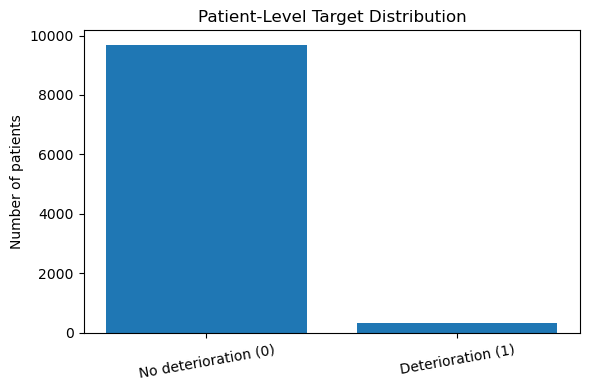

Mean values by target class:


,heart_rate,respiratory_rate,spo2_pct,temperature_c,systolic_bp,lactate,crp_level
deterioration_within_12h_from_admission,,,,,,,
0,84.458,18.536,95.319,36.880,116.654,1.516,24.075
1,89.860,20.706,94.217,36.919,110.689,1.705,28.881


In [7]:
plt.figure(figsize=(6, 4))
counts = admission_df[TARGET].value_counts().reindex([0, 1], fill_value=0)
plt.bar(["No deterioration (0)", "Deterioration (1)"], counts.values)
plt.title("Patient-Level Target Distribution")
plt.ylabel("Number of patients")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

eda_columns = [
    "heart_rate", "respiratory_rate", "spo2_pct",
    "temperature_c", "systolic_bp", "lactate", "crp_level"
]

print("Mean values by target class:")
display(admission_df.groupby(TARGET)[eda_columns].mean().round(3))

In [8]:
FEATURES = [
    "heart_rate",
    "respiratory_rate",
    "spo2_pct",
    "temperature_c",
    "systolic_bp",
    "diastolic_bp",
    "mobility_score",
    "wbc_count",
    "lactate",
    "creatinine",
    "crp_level",
    "hemoglobin",
    "age",
    "gender",
    "comorbidity_index",
    "admission_type"
]

missing_features = [c for c in FEATURES if c not in admission_df.columns]
if missing_features:
    raise ValueError(f"Selected features missing from dataset: {missing_features}")

X = admission_df[FEATURES].copy()
y = admission_df[TARGET].astype(int).copy()
patient_ids = admission_df["patient_id"].copy()

print("Number of patients:", len(X))
print("Number of selected features:", len(FEATURES))
print("Selected features:", FEATURES)
print("\nCategorical features:", X.select_dtypes(exclude="number").columns.tolist())

Number of patients: 10000
Number of selected features: 16
Selected features: ['heart_rate', 'respiratory_rate', 'spo2_pct', 'temperature_c', 'systolic_bp', 'diastolic_bp', 'mobility_score', 'wbc_count', 'lactate', 'creatinine', 'crp_level', 'hemoglobin', 'age', 'gender', 'comorbidity_index', 'admission_type']

Categorical features: ['gender', 'admission_type']


In [9]:
protected_or_unverified_columns = [
    "patient_id", "hour_from_admission", "los_hours",
    "deterioration_event", "deterioration_hour", TARGET,
    "oxygen_device", "oxygen_flow", "nurse_alert",
    "sepsis_risk_score", "baseline_risk_score"
]

feature_overlap = sorted(set(FEATURES).intersection(protected_or_unverified_columns))
missing_selected_features = [c for c in FEATURES if c not in admission_df.columns]

print("Selected primary features:", len(FEATURES))
print("Selected features missing from admission_df:", missing_selected_features)
print("Selected features overlapping excluded/unverified fields:", feature_overlap)

if missing_selected_features:
    print("FAIL: One or more selected features are absent from admission_df.")
elif feature_overlap:
    print("REVIEW REQUIRED: Review the selected features listed above before modelling.")
else:
    print("PASS: The primary feature list excludes the specified identifier, outcome, timing, and unverified fields.")

hour_zero_panel = df.loc[df["hour_from_admission"].eq(0)].copy()
feature_audit_rows = []

feature_groups = {
    "heart_rate": "Vital sign",
    "respiratory_rate": "Vital sign",
    "spo2_pct": "Vital sign",
    "temperature_c": "Vital sign",
    "systolic_bp": "Vital sign",
    "diastolic_bp": "Vital sign",
    "mobility_score": "Clinical/functional measure",
    "wbc_count": "Laboratory measurement",
    "lactate": "Laboratory measurement",
    "creatinine": "Laboratory measurement",
    "crp_level": "Laboratory measurement",
    "hemoglobin": "Laboratory measurement",
    "age": "Demographic/baseline",
    "gender": "Demographic/baseline",
    "comorbidity_index": "Derived baseline measure",
    "admission_type": "Admission metadata"
}

for feature in FEATURES:
    hour0_values = hour_zero_panel[feature]
    unique_values_per_patient = df.groupby("patient_id")[feature].nunique(dropna=True)
    patients_with_hour0_value = int(hour0_values.notna().sum())
    hour0_missing_percent = float(hour0_values.isna().mean() * 100)

    feature_audit_rows.append({
        "Feature": feature,
        "Feature_Group": feature_groups.get(feature, "Review required"),
        "Data_Type": str(df[feature].dtype),
        "Hour0_Patients_With_Value": patients_with_hour0_value,
        "Hour0_Missing_Percent": round(hour0_missing_percent, 2),
        "Patients_Whose_Value_Varies_During_Stay": int((unique_values_per_patient > 1).sum()),
        "Feature_Specific_Measurement_Timestamp_In_CSV": "Not provided/identified",
        "Prediction_Time_Availability_Status": "REQUIRES SOURCE/TIMESTAMP VERIFICATION"
    })

feature_timing_audit = pd.DataFrame(feature_audit_rows)
print("\nFeature timing audit:")
display(feature_timing_audit)

possible_time_columns = [
    c for c in df.columns
    if any(token in c.lower() for token in ["timestamp", "datetime", "measurement_time", "collection_time", "result_time", "_date"])
]
print("\nPotential timestamp/date columns found:", possible_time_columns)
if not possible_time_columns:
    print("No feature-specific measurement/result timestamp columns were identified in this CSV.")

print("\nInterpretation:")
print("1. Hour-0 presence and within-stay changes are descriptive checks only.")
print("2. A changing feature is not automatically leakage; the model uses only its hour-0 row value.")
print("3. A value present in the hour-0 panel is not proof of real-world availability at admission.")
print("4. Confirm collection/result times and derived-feature definitions from the source documentation before claiming deployment-time prediction.")

Selected primary features: 16
Selected features missing from admission_df: []
Selected features overlapping excluded/unverified fields: []
PASS: The primary feature list excludes the specified identifier, outcome, timing, and unverified fields.

Feature timing audit:


,Feature,Feature_Group,Data_Type,Hour0_Patients_With_Value,Hour0_Missing_Percent,Patients_Whose_Value_Varies_During_Stay,Feature_Specific_Measurement_Timestamp_In_CSV,Prediction_Time_Availability_Status
0,heart_rate,Vital sign,float64,10000,0.0,10000,Not provided/identified,REQUIRES SOURCE/TIMESTAMP VERIFICATION
1,respiratory_rate,Vital sign,float64,10000,0.0,10000,Not provided/identified,REQUIRES SOURCE/TIMESTAMP VERIFICATION
2,spo2_pct,Vital sign,float64,10000,0.0,10000,Not provided/identified,REQUIRES SOURCE/TIMESTAMP VERIFICATION
3,temperature_c,Vital sign,float64,10000,0.0,10000,Not provided/identified,REQUIRES SOURCE/TIMESTAMP VERIFICATION
4,systolic_bp,Vital sign,float64,10000,0.0,10000,Not provided/identified,REQUIRES SOURCE/TIMESTAMP VERIFICATION
5,diastolic_bp,Vital sign,float64,10000,0.0,10000,Not provided/identified,REQUIRES SOURCE/TIMESTAMP VERIFICATION
6,mobility_score,Clinical/functional measure,int64,10000,0.0,10000,Not provided/identified,REQUIRES SOURCE/TIMESTAMP VERIFICATION
7,wbc_count,Laboratory measurement,float64,10000,0.0,10000,Not provided/identified,REQUIRES SOURCE/TIMESTAMP VERIFICATION
8,lactate,Laboratory measurement,float64,10000,0.0,10000,Not provided/identified,REQUIRES SOURCE/TIMESTAMP VERIFICATION
9,creatinine,Laboratory measurement,float64,10000,0.0,10000,Not provided/identified,REQUIRES SOURCE/TIMESTAMP VERIFICATION



Potential timestamp/date columns found: []
No feature-specific measurement/result timestamp columns were identified in this CSV.

Interpretation:
1. Hour-0 presence and within-stay changes are descriptive checks only.
2. A changing feature is not automatically leakage; the model uses only its hour-0 row value.
3. A value present in the hour-0 panel is not proof of real-world availability at admission.
4. Confirm collection/result times and derived-feature definitions from the source documentation before claiming deployment-time prediction.


In [10]:
X_train, X_test, y_train, y_test, pid_train, pid_test = train_test_split(
    X,
    y,
    patient_ids,
    test_size=0.20,
    random_state=2026,
    stratify=y
)

train_patient_ids = set(pid_train.tolist())
test_patient_ids = set(pid_test.tolist())
overlap = train_patient_ids.intersection(test_patient_ids)

print("Training patients:", len(X_train))
print("Testing patients:", len(X_test))
print("Patients in both sets:", len(overlap))
print("Positive training patients:", int(y_train.sum()))
print("Positive testing patients:", int(y_test.sum()))

if overlap:
    raise ValueError("Patient overlap detected between train and test sets.")

print("Patient separation verified.")

Training patients: 8000
Testing patients: 2000
Patients in both sets: 0
Positive training patients: 247
Positive testing patients: 62
Patient separation verified.


In [11]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


def make_preprocessor(scale_numeric=False):
    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipeline = Pipeline(steps=numeric_steps)

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer(transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

print("Preprocessing functions ready.")

Numeric features: ['heart_rate', 'respiratory_rate', 'spo2_pct', 'temperature_c', 'systolic_bp', 'diastolic_bp', 'mobility_score', 'wbc_count', 'lactate', 'creatinine', 'crp_level', 'hemoglobin', 'age', 'comorbidity_index']
Categorical features: ['gender', 'admission_type']
Preprocessing functions ready.


In [12]:
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count

print("Training negatives:", negative_count)
print("Training positives:", positive_count)
print("XGBoost scale_pos_weight:", round(scale_pos_weight, 2))


def make_model(model_name):
    if model_name == "Logistic Regression":
        classifier = LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
        scale_numeric = True

    elif model_name == "Random Forest":
        classifier = RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced_subsample",
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
        scale_numeric = False

    elif model_name == "XGBoost":
        classifier = XGBClassifier(
            n_estimators=200,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_pos_weight,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )
        scale_numeric = False

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return Pipeline(steps=[
        ("preprocessor", make_preprocessor(scale_numeric=scale_numeric)),
        ("classifier", classifier)
    ])

MODEL_NAMES = ["Logistic Regression", "Random Forest", "XGBoost"]
models = {name: make_model(name) for name in MODEL_NAMES}
print("All three models configured.")

Training negatives: 7753
Training positives: 247
XGBoost scale_pos_weight: 31.39
All three models configured.


In [13]:
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
thresholds_by_model = {}
oof_probabilities = {}

for name, model in models.items():
    print("Getting training out-of-fold probabilities:", name)

    oof_prob = cross_val_predict(
        clone(model),
        X_train,
        y_train,
        cv=inner_cv,
        method="predict_proba",
        n_jobs=1
    )[:, 1]

    oof_probabilities[name] = oof_prob

    precision, recall, thresholds = precision_recall_curve(y_train, oof_prob)
    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    best_f1_idx = int(np.argmax(f1_values))
    f1_threshold = float(thresholds[best_f1_idx])

    eligible = np.flatnonzero(recall[:-1] >= 0.80)
    if len(eligible) > 0:
        best_recall_idx = int(eligible[np.argmax(precision[eligible])])
        recall_threshold = float(thresholds[best_recall_idx])
    else:
        recall_threshold = np.nan

    thresholds_by_model[name] = {
        "F1-optimal": f1_threshold,
        "Recall-focused (80%)": recall_threshold
    }

threshold_table = pd.DataFrame.from_dict(
    thresholds_by_model, orient="index"
)
threshold_table.index.name = "Model"
print("Thresholds selected using training folds only:")
display(threshold_table.round(4))

Getting training out-of-fold probabilities: Logistic Regression
Getting training out-of-fold probabilities: Random Forest
Getting training out-of-fold probabilities: XGBoost
Thresholds selected using training folds only:


,F1-optimal,Recall-focused (80%)
Model,,
Logistic Regression,0.7990,0.3961
Random Forest,0.1229,0.0330
XGBoost,0.6760,0.2355


In [14]:
from sklearn.model_selection import RepeatedStratifiedKFold

REPEATED_CV_SPLITS = 5
REPEATED_CV_REPEATS = 2
repeated_cv = RepeatedStratifiedKFold(
    n_splits=REPEATED_CV_SPLITS,
    n_repeats=REPEATED_CV_REPEATS,
    random_state=2026
)

cv_rows = []

for split_number, (fit_idx, val_idx) in enumerate(
    repeated_cv.split(X_train, y_train), start=1
):
    X_fit = X_train.iloc[fit_idx]
    X_val = X_train.iloc[val_idx]
    y_fit = y_train.iloc[fit_idx]
    y_val = y_train.iloc[val_idx]

    fold_negative_count = int((y_fit == 0).sum())
    fold_positive_count = int((y_fit == 1).sum())

    for model_name in MODEL_NAMES:
        if model_name == "Logistic Regression":
            classifier = LogisticRegression(
                class_weight="balanced",
                max_iter=2000,
                random_state=42
            )
            scale_numeric = True

        elif model_name == "Random Forest":
            classifier = RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced_subsample",
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
            scale_numeric = False

        elif model_name == "XGBoost":
            fold_scale_pos_weight = fold_negative_count / max(fold_positive_count, 1)
            classifier = XGBClassifier(
                n_estimators=200,
                max_depth=3,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=fold_scale_pos_weight,
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
            scale_numeric = False

        else:
            raise ValueError(f"Unknown model: {model_name}")

        fold_pipeline = Pipeline(steps=[
            ("preprocessor", make_preprocessor(scale_numeric=scale_numeric)),
            ("classifier", classifier)
        ])
        fold_pipeline.fit(X_fit, y_fit)
        validation_probabilities = fold_pipeline.predict_proba(X_val)[:, 1]
        validation_predictions = (validation_probabilities >= 0.50).astype(int)

        cv_rows.append({
            "Model": model_name,
            "Validation_Split": split_number,
            "Positive_Validation_Patients": int(y_val.sum()),
            "ROC-AUC": roc_auc_score(y_val, validation_probabilities),
            "Average_Precision": average_precision_score(y_val, validation_probabilities),
            "Precision_at_0.50": precision_score(y_val, validation_predictions, zero_division=0),
            "Recall_at_0.50": recall_score(y_val, validation_predictions, zero_division=0),
            "F1_at_0.50": f1_score(y_val, validation_predictions, zero_division=0)
        })

cv_results_df = pd.DataFrame(cv_rows)
cv_metric_columns = [
    "ROC-AUC", "Average_Precision", "Precision_at_0.50",
    "Recall_at_0.50", "F1_at_0.50"
]
cv_summary = cv_results_df.groupby("Model")[cv_metric_columns].agg(["mean", "std"])

print(f"CV splits per model: {REPEATED_CV_SPLITS * REPEATED_CV_REPEATS}")
print("Number of result rows:", len(cv_results_df))
print("\nRepeated CV summary (mean and standard deviation across validation folds):")
display(cv_summary.round(4))
print("\nFirst validation-fold results:")
display(cv_results_df.head(15).round(4))

print("\nInterpretation note: Use ROC-AUC and Average Precision to compare ranking performance across folds.")
print("Large fold-to-fold standard deviations indicate more variation. This training-only analysis does not replace the held-out test result or external validation.")

CV splits per model: 10
Number of result rows: 30

Repeated CV summary (mean and standard deviation across validation folds):


ROC-AUC         Average_Precision          \
                       mean     std              mean     std   
Model                                                           
Logistic Regression  0.7644  0.0370            0.1050  0.0306   
Random Forest        0.7188  0.0277            0.0807  0.0147   
XGBoost              0.7221  0.0366            0.0812  0.0201   

                    Precision_at_0.50         Recall_at_0.50          \
                                 mean     std           mean     std   
Model                                                                  
Logistic Regression            0.0683  0.0055         0.6884  0.0809   
Random Forest                  0.0000  0.0000         0.0000  0.0000   
XGBoost                        0.0662  0.0098         0.4493  0.0759   

                    F1_at_0.50          
                          mean     std  
Model                                   
Logistic Regression     0.1242  0.0104  
Random Forest           0.0000  0.0000  
XGBoost                 0.1154  0.0173


First validation-fold results:


,Model,Validation_Split,Positive_Validation_Patients,ROC-AUC,Average_Precision,Precision_at_0.50,Recall_at_0.50,F1_at_0.50
0,Logistic Regression,1,49,0.7342,0.0820,0.0642,0.6122,0.1163
1,Random Forest,1,49,0.6897,0.1135,0.0000,0.0000,0.0000
2,XGBoost,1,49,0.6890,0.0807,0.0623,0.4082,0.1081
3,Logistic Regression,2,49,0.7409,0.0723,0.0667,0.6939,0.1216
4,Random Forest,2,49,0.6889,0.0653,0.0000,0.0000,0.0000
5,XGBoost,2,49,0.6955,0.0656,0.0547,0.3673,0.0952
6,Logistic Regression,3,49,0.8084,0.1683,0.0735,0.7755,0.1343
7,Random Forest,3,49,0.7230,0.0693,0.0000,0.0000,0.0000
8,XGBoost,3,49,0.7198,0.0726,0.0633,0.4286,0.1102
9,Logistic Regression,4,50,0.7399,0.0857,0.0630,0.6200,0.1144



Interpretation note: Use ROC-AUC and Average Precision to compare ranking performance across folds.
Large fold-to-fold standard deviations indicate more variation. This training-only analysis does not replace the held-out test result or external validation.


In [15]:
trained_models = {}
test_probabilities = {}
results = []

for name, model in models.items():
    print("Fitting final training model:", name)
    model.fit(X_train, y_train)
    trained_models[name] = model

    y_prob = model.predict_proba(X_test)[:, 1]
    test_probabilities[name] = y_prob

    # Threshold-independent metrics: calculated once per model
    test_roc_auc = roc_auc_score(y_test, y_prob)
    test_ap = average_precision_score(y_test, y_prob)

    strategies = {"Default 0.50": 0.50}
    strategies.update(thresholds_by_model[name])

    for strategy, threshold in strategies.items():
        if pd.isna(threshold):
            continue

        y_pred = (y_prob >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y_test, y_pred, labels=[0, 1]
        ).ravel()

        results.append({
            "Model": name,
            "Threshold Strategy": strategy,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1-Score": f1_score(y_test, y_pred, zero_division=0),
            "ROC-AUC": test_roc_auc,
            "Average Precision": test_ap,
            "True Negatives": tn,
            "False Positives": fp,
            "False Negatives": fn,
            "True Positives": tp
        })

results_df = pd.DataFrame(results)
print("Test results. Thresholds were selected using training data only:")
display(results_df.round(4))

Fitting final training model: Logistic Regression
Fitting final training model: Random Forest
Fitting final training model: XGBoost
Test results. Thresholds were selected using training data only:


,Model,Threshold Strategy,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Precision,True Negatives,False Positives,False Negatives,True Positives
0,Logistic Regression,Default 0.50,0.5000,0.6925,0.7008,0.0686,0.7097,0.1252,0.7696,0.1303,1341,597,18,44
1,Logistic Regression,F1-optimal,0.7990,0.9260,0.5949,0.1293,0.2419,0.1685,0.7696,0.1303,1837,101,47,15
2,Logistic Regression,Recall-focused (80%),0.3961,0.5775,0.6961,0.0576,0.8226,0.1077,0.7696,0.1303,1104,834,11,51
3,Random Forest,Default 0.50,0.5000,0.9690,0.5000,0.0000,0.0000,0.0000,0.7447,0.1205,1938,0,62,0
4,Random Forest,F1-optimal,0.1229,0.9170,0.5825,0.1061,0.2258,0.1443,0.7447,0.1205,1820,118,48,14
5,Random Forest,Recall-focused (80%),0.0330,0.5650,0.6741,0.0541,0.7903,0.1012,0.7447,0.1205,1081,857,13,49
6,XGBoost,Default 0.50,0.5000,0.7560,0.6789,0.0740,0.5968,0.1317,0.7413,0.0958,1475,463,25,37
7,XGBoost,F1-optimal,0.6760,0.8925,0.5776,0.0820,0.2419,0.1224,0.7413,0.0958,1770,168,47,15
8,XGBoost,Recall-focused (80%),0.2355,0.5065,0.6751,0.0514,0.8548,0.0970,0.7413,0.0958,960,978,9,53


In [16]:
from itertools import combinations

N_BOOTSTRAPS = 2000
BOOTSTRAP_SEED = 2026
rng = np.random.default_rng(BOOTSTRAP_SEED)

y_test_array = np.asarray(y_test).astype(int)
positive_indices = np.flatnonzero(y_test_array == 1)
negative_indices = np.flatnonzero(y_test_array == 0)

if len(positive_indices) == 0 or len(negative_indices) == 0:
    raise ValueError("Bootstrap evaluation requires positive and negative test patients.")

bootstrap_metric_names = [
    "ROC-AUC", "Average Precision", "Precision", "Recall", "F1-Score"
]
bootstrap_values = {
    model_name: {metric: [] for metric in bootstrap_metric_names}
    for model_name in MODEL_NAMES
}

point_estimates = {}
for model_name in MODEL_NAMES:
    test_prob = np.asarray(test_probabilities[model_name])
    f1_threshold = thresholds_by_model[model_name]["F1-optimal"]
    test_pred = (test_prob >= f1_threshold).astype(int)

    point_estimates[model_name] = {
        "ROC-AUC": roc_auc_score(y_test_array, test_prob),
        "Average Precision": average_precision_score(y_test_array, test_prob),
        "Precision": precision_score(y_test_array, test_pred, zero_division=0),
        "Recall": recall_score(y_test_array, test_pred, zero_division=0),
        "F1-Score": f1_score(y_test_array, test_pred, zero_division=0)
    }

# Use the same sampled test-patient indices for all models in each replicate
# so pairwise model differences are paired comparisons.
for bootstrap_number in range(N_BOOTSTRAPS):
    sampled_positive = rng.choice(
        positive_indices, size=len(positive_indices), replace=True
    )
    sampled_negative = rng.choice(
        negative_indices, size=len(negative_indices), replace=True
    )
    sampled_indices = np.concatenate([sampled_negative, sampled_positive])
    y_boot = y_test_array[sampled_indices]

    for model_name in MODEL_NAMES:
        probabilities_boot = np.asarray(test_probabilities[model_name])[sampled_indices]
        fixed_threshold = thresholds_by_model[model_name]["F1-optimal"]
        predictions_boot = (probabilities_boot >= fixed_threshold).astype(int)

        bootstrap_values[model_name]["ROC-AUC"].append(
            roc_auc_score(y_boot, probabilities_boot)
        )
        bootstrap_values[model_name]["Average Precision"].append(
            average_precision_score(y_boot, probabilities_boot)
        )
        bootstrap_values[model_name]["Precision"].append(
            precision_score(y_boot, predictions_boot, zero_division=0)
        )
        bootstrap_values[model_name]["Recall"].append(
            recall_score(y_boot, predictions_boot, zero_division=0)
        )
        bootstrap_values[model_name]["F1-Score"].append(
            f1_score(y_boot, predictions_boot, zero_division=0)
        )

bootstrap_ci_rows = []
for model_name in MODEL_NAMES:
    for metric in bootstrap_metric_names:
        bootstrap_scores = np.asarray(bootstrap_values[model_name][metric])
        ci_lower, ci_upper = np.percentile(bootstrap_scores, [2.5, 97.5])
        bootstrap_ci_rows.append({
            "Model": model_name,
            "Metric": metric,
            "Threshold_Used": thresholds_by_model[model_name]["F1-optimal"] if metric in ["Precision", "Recall", "F1-Score"] else np.nan,
            "Test_Point_Estimate": point_estimates[model_name][metric],
            "95%_CI_Lower": ci_lower,
            "95%_CI_Upper": ci_upper
        })

bootstrap_ci_df = pd.DataFrame(bootstrap_ci_rows)
print("Bootstrap replicates:", N_BOOTSTRAPS)
print("Positive test patients:", len(positive_indices))
print("Negative test patients:", len(negative_indices))
print("\nPoint estimates and 95% percentile confidence intervals:")
display(bootstrap_ci_df.round(4))

# Paired bootstrap intervals for differences between models.
# Positive difference means Model_A's metric is higher than Model_B's.
pairwise_rows = []
for model_a, model_b in combinations(MODEL_NAMES, 2):
    for metric in ["ROC-AUC", "Average Precision"]:
        values_a = np.asarray(bootstrap_values[model_a][metric])
        values_b = np.asarray(bootstrap_values[model_b][metric])
        paired_difference = values_a - values_b
        difference_lower, difference_upper = np.percentile(
            paired_difference, [2.5, 97.5]
        )

        pairwise_rows.append({
            "Metric": metric,
            "Model_A": model_a,
            "Model_B": model_b,
            "Point_Difference_A_minus_B": (
                point_estimates[model_a][metric] - point_estimates[model_b][metric]
            ),
            "95%_CI_Lower": difference_lower,
            "95%_CI_Upper": difference_upper,
            "CI_Includes_Zero": bool(difference_lower <= 0 <= difference_upper)
        })

bootstrap_pairwise_df = pd.DataFrame(pairwise_rows)
print("\nPaired bootstrap intervals for model-performance differences:")
display(bootstrap_pairwise_df.round(4))

print("\nInterpretation: If a paired difference interval includes zero, this test set does not clearly establish the direction of that pairwise difference.")
print("These intervals do not establish clinical readiness or performance on other hospitals/populations.")

Bootstrap replicates: 2000
Positive test patients: 62
Negative test patients: 1938

Point estimates and 95% percentile confidence intervals:


,Model,Metric,Threshold_Used,Test_Point_Estimate,95%_CI_Lower,95%_CI_Upper
0,Logistic Regression,ROC-AUC,NaN,0.7696,0.7122,0.8237
1,Logistic Regression,Average Precision,NaN,0.1303,0.0804,0.2097
2,Logistic Regression,Precision,0.7990,0.1293,0.0787,0.1842
3,Logistic Regression,Recall,0.7990,0.2419,0.1452,0.3548
4,Logistic Regression,F1-Score,0.7990,0.1685,0.1026,0.2386
5,Random Forest,ROC-AUC,NaN,0.7447,0.6822,0.7989
6,Random Forest,Average Precision,NaN,0.1205,0.0736,0.2144
7,Random Forest,Precision,0.1229,0.1061,0.0620,0.1560
8,Random Forest,Recall,0.1229,0.2258,0.1290,0.3387
9,Random Forest,F1-Score,0.1229,0.1443,0.0842,0.2090



Paired bootstrap intervals for model-performance differences:


,Metric,Model_A,Model_B,Point_Difference_A_minus_B,95%_CI_Lower,95%_CI_Upper,CI_Includes_Zero
0,ROC-AUC,Logistic Regression,Random Forest,0.0250,-0.0159,0.0679,True
1,Average Precision,Logistic Regression,Random Forest,0.0098,-0.0811,0.0906,True
2,ROC-AUC,Logistic Regression,XGBoost,0.0283,-0.0055,0.0660,True
3,Average Precision,Logistic Regression,XGBoost,0.0345,-0.0388,0.1004,True
4,ROC-AUC,Random Forest,XGBoost,0.0034,-0.0327,0.0401,True
5,Average Precision,Random Forest,XGBoost,0.0247,-0.0129,0.0719,True



Interpretation: If a paired difference interval includes zero, this test set does not clearly establish the direction of that pairwise difference.
These intervals do not establish clinical readiness or performance on other hospitals/populations.


In [17]:
main_comparison = results_df.loc[
    results_df["Threshold Strategy"] == "F1-optimal",
    [
        "Model", "Threshold", "Accuracy", "Balanced Accuracy",
        "Precision", "Recall", "F1-Score", "ROC-AUC",
        "Average Precision", "False Positives", "False Negatives",
        "True Positives", "True Negatives"
    ]
].copy()

main_comparison = main_comparison.sort_values(
    "ROC-AUC", ascending=False
).reset_index(drop=True)

display(main_comparison.round(4))

,Model,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Precision,False Positives,False Negatives,True Positives,True Negatives
0,Logistic Regression,0.7990,0.9260,0.5949,0.1293,0.2419,0.1685,0.7696,0.1303,101,47,15,1837
1,Random Forest,0.1229,0.9170,0.5825,0.1061,0.2258,0.1443,0.7447,0.1205,118,48,14,1820
2,XGBoost,0.6760,0.8925,0.5776,0.0820,0.2419,0.1224,0.7413,0.0958,168,47,15,1770
